# Aufgabe 1.1

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from netgen.meshing import Element0D, Element1D, Mesh as NGMesh, MeshPoint, Pnt
from ngsolve import *
from ngsolve.webgui import Draw

## 1.1.1

$$\int_{\Omega} \nabla u \cdot \nabla v \, \mathrm{d}x = \int_{\Omega} 1 \cdot v \, \mathrm{d}x \quad \forall v \in V$$

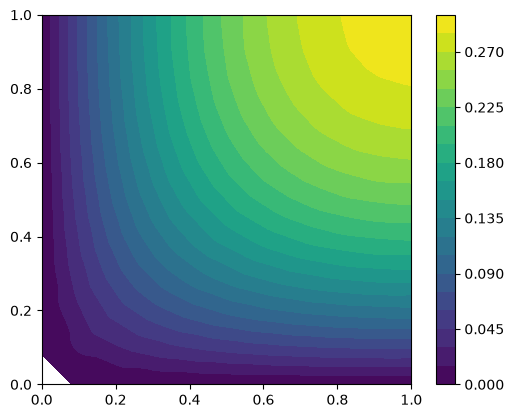

In [6]:
## 1.1.2
mesh = Mesh(unit_square.GenerateMesh(maxh=0.1))
V = H1(mesh, order=1, dirichlet='bottom|left')
u, v = V.TnT()
gfu = GridFunction(V)

a = BilinearForm(V)
a += grad(u) * grad(v) * dx
a.Assemble()

f = LinearForm(V)
f += 1 * v * dx
f.Assemble()

gfu.vec.data = a.mat.Inverse(freedofs=V.FreeDofs()) * f.vec

# Plot ohne WebGUI (kein anywidget-Error)
xs = np.linspace(0, 1, 50)
ys = np.linspace(0, 1, 50)
X, Y = np.meshgrid(xs, ys)
Z = np.vectorize(lambda x, y: gfu(mesh(x, y)))(X, Y)

plt.contourf(X, Y, Z, levels=20, cmap="viridis")
plt.colorbar()
plt.gca().set_aspect("equal")
plt.show()

## 1.1.3

$$\int_{\Omega} \nabla u \cdot \nabla v \, \mathrm{d}x - \int_{\Gamma_2} 1 \cdot v \, \mathrm{d}S = \int_{\Omega} 1 \cdot v \, \mathrm{d}x \quad \forall v \in V$$

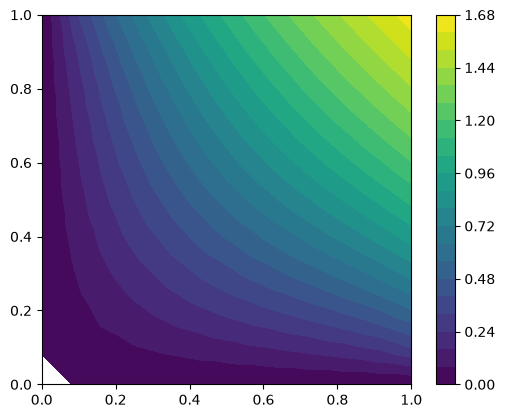

In [7]:
# 1.1.4
f1 = LinearForm(V)
f1 += 1 * v * dx
f1 += 1 * v * ds(definedon=mesh.Boundaries('right|top'))
f1.Assemble()

gfu1 = GridFunction(V)
gfu1.vec.data = a.mat.Inverse(freedofs=V.FreeDofs()) * f1.vec

# Plot ohne WebGUI (kein anywidget-Error)
Z1 = np.vectorize(lambda x, y: gfu1(mesh(x, y)))(X, Y)

plt.contourf(X, Y, Z1, levels=20, cmap="viridis")
plt.colorbar()
plt.gca().set_aspect("equal")
plt.show()

# 2.2

In [4]:
import matplotlib.pyplot as plt
import numpy as np
from ngsolve import *
from ngsolve.meshes import MakeStructured2DMesh
from scipy.integrate import dblquad

Eigene 2D-FEM Lösung: [0.       0.       0.       0.       0.166667 0.208333 0.       0.208333
 0.25    ]
NGSolve 2D-FEM Lösung: [0.       0.       0.       0.       0.166667 0.208333 0.       0.208333
 0.25    ]


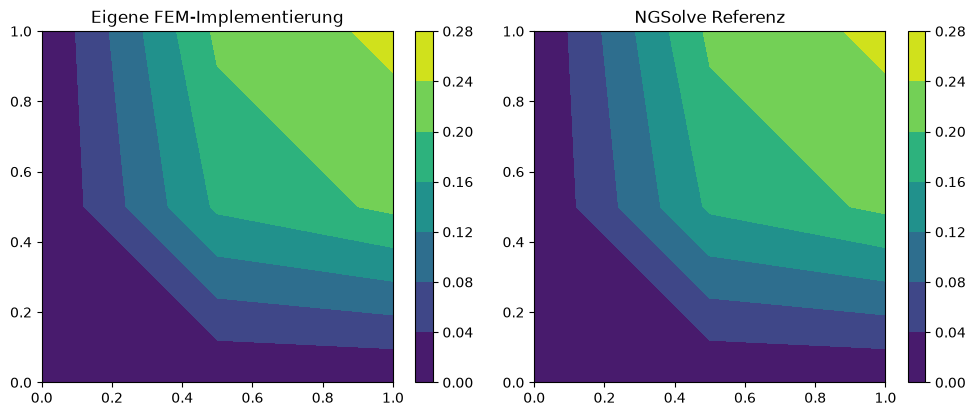

In [8]:
# 1. Referenz-Basisfunktionen & Gradienten auf dem Einheitsdreieck
def myshape(t, j):
    xi, eta = t
    if j == 0:
        return 1 - xi - eta
    elif j == 1:
        return xi
    else:
        return eta

def Dmyshape(t, j):
    if j == 0:
        return np.array([-1.0, -1.0])
    elif j == 1:
        return np.array([1.0, 0.0])
    else:
        return np.array([0.0, 1.0])

def quadT(f):
    return dblquad(f, 0, 1, 0, lambda x: 1 - x)[0]

# 2. Strukturiertes 2D-Gitter (3x3 Punkte = 8 Dreiecke)
pts = np.array([
    [0.0, 0.0], [0.5, 0.0], [1.0, 0.0],
    [0.0, 0.5], [0.5, 0.5], [1.0, 0.5],
    [0.0, 1.0], [0.5, 1.0], [1.0, 1.0]
])

# Knotenindizes der 8 Dreiecke (0-basiert)
T = np.array([
    [1, 2, 4], [2, 5, 4],
    [2, 3, 5], [3, 6, 5],
    [4, 5, 7], [5, 8, 7],
    [5, 6, 8], [6, 9, 8]
]) - 1

# 3. Koordinatentransformation & Globales Assembling
def CnJ(p1, p2, p3):
    B = np.array([(p2 - p1), (p3 - p1)]).T
    invB = np.linalg.inv(B)
    return invB @ invB.T, np.linalg.det(B)

def myfun(x, y):
    return 1.0

N = pts.shape[0]
A = np.zeros((N, N))
f = np.zeros(N)

for t in T:
    Ci, Ji = CnJ(*pts[t])
    Ai = np.array([
        [quadT(lambda x, y: Dmyshape([x, y], j) @ Ci @ Dmyshape([x, y], k)) * Ji for k in range(3)]
        for j in range(3)
    ])
    A[np.ix_(t, t)] += Ai

    fi = np.array([
        quadT(lambda x, y: myshape([x, y], j) * myfun(x, y) * Ji)
        for j in range(3)
    ])
    f[t] += fi

# 4. Freie Freiheitsgrade lösen (Dirichlet u=0 auf Knoten 0,1,2,3,6 -> frei: 4,5,7,8)
freedofs = np.array([4, 5, 7, 8])
sol = np.zeros(N)
sol[freedofs] = np.linalg.solve(A[np.ix_(freedofs, freedofs)], f[freedofs])

print("Eigene 2D-FEM Lösung:", np.round(sol, 6))

# 5. Vergleich mit NGSolve auf exakt demselben strukturierten Mesh
mesh = MakeStructured2DMesh(quads=False, nx=2, ny=2)
V = H1(mesh, order=1, dirichlet="bottom|left")
u, v = V.TnT()

a_ngs = BilinearForm(V)
a_ngs += grad(u) * grad(v) * dx
a_ngs.Assemble()

b_ngs = LinearForm(V)
b_ngs += 1 * v * dx
b_ngs.Assemble()

gfu = GridFunction(V)
gfu.vec.data = a_ngs.mat.Inverse(freedofs=V.FreeDofs()) * b_ngs.vec

print("NGSolve 2D-FEM Lösung:", np.round(np.array(gfu.vec), 6))

# 6. Konturplot der beiden Lösungen nebeneinander
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
X, Y = pts[:, 0].reshape(3, 3), pts[:, 1].reshape(3, 3)

c1 = axes[0].contourf(X, Y, sol.reshape(3, 3))
axes[0].set_title("Eigene FEM-Implementierung")
axes[0].set_aspect(1)
fig.colorbar(c1, ax=axes[0])

c2 = axes[1].contourf(X, Y, np.array(gfu.vec).reshape(3, 3))
axes[1].set_title("NGSolve Referenz")
axes[1].set_aspect(1)
fig.colorbar(c2, ax=axes[1])

plt.tight_layout()
plt.show()